# BDT selection optimisation (binned FOM, coordinate descent)

Driver for `bdt_cut_optimization.py`. Signal = $D\tau\nu$; background = the six non-physics
categories the BDT suppresses. FOM summed over the signal-region fit bins (`MM2_bins_sr` x
`p_D_l_bins_sr`) after MVA cut -> BCS -> D_M window, e and mu combined in quadrature.

* Optimise on **run2 generic MC half A** (even event number), validate on **half B**.
* Independent cross-check on **run1 mu** (run1 e was partly used in the BDT training).
* Needs candidate-level samples (no MVA cut, no BCS): the `MC_*_loose` trees are already
  post-BCS after `lgb_loose`, so they cannot be used here.

### Target function and the 10-event bin threshold

In one bin, $s, b$ are the *expected* MC counts and $\hat s, \hat b$ the counts found in the sample,
$n=\hat s+\hat b \sim \mathrm{Poisson}(s+b)$. Given $n$, each event is signal with probability $p=s/(s+b)$,
so $\hat s \mid n \sim \mathrm{Binomial}(n, p)$ with mean $np$ and variance $np(1-p)$.

**Plain estimator** $\hat s^2/n$ (`estimator='plain'`). From $E[\hat s^2 \mid n] = np(1-p) + n^2p^2$ and averaging over $n$
($E[f]=\sum_n P(n)\,E[f\mid n]$):

$$E\!\left[\frac{\hat s^2}{n}\right] = \frac{s^2}{s+b} + \underbrace{p(1-p)\left(1-e^{-(s+b)}\right)}_{\text{excess}}$$

* The excess depends on the purity, not on the bin size: about $p(1-p)$, at most 0.25 (at $p=0.5$).
* Relative to the bin's true contribution it is $(1-p)/s$: tiny with many signal events, as large as the whole
  contribution in nearly empty bins.
* A looser cut fills more sparse bins, each adding its excess, so MC statistics alone push the plain FOM
  toward looser cuts. The $n\ge10$ threshold removes the sparse bins but leaves up to 0.25 per kept bin.

**Default estimator** $\hat s(\hat s-1)/(n-1)$ (`estimator='unbiased'`). The second factorial moment of the binomial is

$$E[\hat s(\hat s-1)\mid n] = np(1-p)+n^2p^2-np = n(n-1)p^2 \;\Rightarrow\; E\!\left[\frac{\hat s(\hat s-1)}{n-1}\,\Big|\, n\right]=np^2 ,$$

the unbiased part of the plain term, with no $p(1-p)$ term. Why it is better:
* no excess at any purity or bin size, so MC statistics cannot move the optimum;
* bin by bin it is the plain term minus the estimated excess, $\hat s^2/n-\hat s(\hat s-1)/(n-1)=\hat p(1-\hat p)\,n/(n-1)$,
  i.e. the same FOM with the bias removed, not a different measure; the two agree for large $n$;
* it is exact for every $n\ge2$, so the $n\ge10$ selection keeps it exact (the threshold stays because the fit
  also drops sparse bins);
* same inputs and cost. Exact for raw MC counts and `eps_bkg = 0`; approximate for `eps_bkg > 0`.

`excess_frac` $=\sum_\text{kept}\hat p(1-\hat p)/Z^2$ is the share of $Z^2$ the plain estimator would add.
Thresholds are rounded to 3 decimals (`make_grids(..., decimals=3)`; use 2 for coarser numbers).

In [1]:
%load_ext autoreload
%autoreload 2
import glob, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append('/home/belle/zhangboy/inclusive_R_D/')
import utilities as util
import bdt_cut_optimization as bco

SAMPLES = '/home/belle/zhangboy/inclusive_R_D/Samples'
CACHE = f'{SAMPLES}/bdt_cut_optimization'     # compact candidate-level frames
PLOTS = 'Plotting/plots/bdt_cut_optimization'
os.makedirs(CACHE, exist_ok=True); os.makedirs(PLOTS, exist_ok=True)

## 1. Load candidate-level generic MC (run once; cached)

In [2]:
def load_cached(run, mode, extra_cut=None):
    path = f'{CACHE}/4S_{run}_{mode}_candidates.pkl'
    if os.path.exists(path):
        return pd.read_pickle(path)
    files = sorted(glob.glob(f'{SAMPLES}/MC16rd/4S_{run}_deimos_1/*.root'))
    df = bco.load_candidates(files, mode, extra_cut=extra_cut)
    df.to_pickle(path)
    return df

# D* veto off by default (extra_cut=util.Dst_veto_cut to switch it on)
dfs_run2 = {m: load_cached('run2', m) for m in ('e', 'mu')}
df_run1_mu = load_cached('run1', 'mu')
for k, d in dfs_run2.items():
    print(k, len(d), d['category'].value_counts().to_dict())

[e] chunk 0: 1,701,683 candidates
[e] chunk 1: 2,765,029 candidates
[e] chunk 2: 168,846 candidates
[e] chunk 3: 34,420 candidates
[e] chunk 4: 2,890,887 candidates
[e] chunk 5: 677,096 candidates
[e] chunk 6: 50,419 candidates
[e] chunk 7: 137,553 candidates
[mu] chunk 0: 1,161,575 candidates
[mu] chunk 1: 2,024,342 candidates
[mu] chunk 2: 42,163 candidates
[mu] chunk 3: 2,411,340 candidates
[mu] chunk 4: 57,447 candidates
[mu] chunk 5: 166,183 candidates
[mu] chunk 0: 2,237,331 candidates
[mu] chunk 1: 209,069 candidates
[mu] chunk 2: 3,201,256 candidates
[mu] chunk 3: 1,205,477 candidates
[mu] chunk 4: 90,671 candidates
[mu] chunk 5: 3,329,750 candidates
[mu] chunk 6: 1,896,568 candidates
[mu] chunk 7: 119,820 candidates
[mu] chunk 8: 358,411 candidates
e 8425933 {'bkg_fakeD': 6904019, 'bkg_continuum': 318262, 'bkg_combinatorial': 301909, '$D\\ell\\nu$': 240599, '$D^\\ast\\ell\\nu$': 186714, 'bkg_fakeTracks': 158778, 'bkg_hadronicB_secondaryL': 101531, '$D^{\\ast\\ast}\\ell\\nu$_na

In [3]:
# Raw MC counts (no luminosity scaling): Z is in MC units, the optimum does not depend on it.
# Only fit bins with >= 10 MC candidates of signal + background enter the FOM
# (min_bin_count=10, count_on='fom'; count_on='all' counts every category, like the templates).
data = bco.FOMInput(dfs_run2)
data_run1_mu = bco.FOMInput({'mu': df_run1_mu})
data.describe()

,channel,half,candidates,events,signal_cands,bkg_cands
0,e,A,4215269,3572946,5889,3902905
1,e,B,4210664,3572137,5628,3898124
2,mu,A,2931045,2492685,3027,2673617
3,mu,B,2932005,2493470,2951,2674018


## 2. Old vs. new selection chain
* **new chain (nominal, `cut_then_bcs`)**: lgb_loose without BCS, then lgb_tight, then BCS.
  Since lgb_tight implies lgb_loose this is exactly MVA cut -> BCS.
* **old chain**: lgb_loose -> BCS -> lgb_tight (the current `MC_*_loose` trees);
  reproduced by `bcs_order='bcs_then_cut', bcs_base=util.lgb_loose`.

`n_bins` is the number of fit bins passing the 10-event threshold.

In [4]:
old_chain = dict(bcs_order='bcs_then_cut', bcs_base=util.lgb_loose)
pd.DataFrame([
    dict(chain='new: cut -> BCS', **bco.evaluate_cut(data, util.lgb_tight, half='all')),
    dict(chain='old: loose -> BCS -> tight', **bco.evaluate_cut(data, util.lgb_tight, half='all', **old_chain)),
])

,chain,sig_prob,fakeD_prob,continuum_prob,combinatorial_prob,Z_e,Z_mu,Z,n_bins,S,B,excess_frac
0,new: cut -> BCS,0.5,0.06,0.4,0.6,14.831351,10.184496,17.991468,1242,3897.0,73844.0,0.148337
1,old: loose -> BCS -> tight,0.5,0.06,0.4,0.6,14.852915,10.196501,18.016041,1233,3858.0,71678.0,0.149047


## 3. Coordinate descent from three starting points (half A)

In [5]:
res = bco.run_optimization(data, half='A')       # starts: open, lgb_tight, lgb_loose
res['paths'].to_csv(f'{PLOTS}/descent_paths.csv', index=False)
res['summary']

[open] start Z=7.8881  (no cut)
[open] sweep 1: Z=14.2938  sig_prob>0.585 and fakeD_prob<0.172
[open] sweep 2: Z=14.6023  sig_prob>0.384 and fakeD_prob<0.199 and continuum_prob<0.572
[open] sweep 3: Z=14.6023  sig_prob>0.384 and fakeD_prob<0.199 and continuum_prob<0.572
[lgb_tight] start Z=12.8503  sig_prob>0.5 and fakeD_prob<0.06 and continuum_prob<0.4 and combinatorial_prob<0.6
[lgb_tight] sweep 1: Z=14.5626  sig_prob>0.5 and fakeD_prob<0.172 and combinatorial_prob<0.459
[lgb_tight] sweep 2: Z=14.6023  sig_prob>0.384 and fakeD_prob<0.199 and continuum_prob<0.572
[lgb_tight] sweep 3: Z=14.6023  sig_prob>0.384 and fakeD_prob<0.199 and continuum_prob<0.572
[lgb_loose] start Z=14.1976  sig_prob>0.2 and fakeD_prob<0.15 and continuum_prob<0.5 and combinatorial_prob<0.6
[lgb_loose] sweep 1: Z=14.5626  sig_prob>0.5 and fakeD_prob<0.172 and combinatorial_prob<0.459
[lgb_loose] sweep 2: Z=14.6023  sig_prob>0.384 and fakeD_prob<0.199 and continuum_prob<0.572
[lgb_loose] sweep 3: Z=14.6023  sig_

,start,Z,restarts,cut,sig_prob,fakeD_prob,continuum_prob,combinatorial_prob
0,open,14.602264,0,sig_prob>0.384 and fakeD_prob<0.199 and contin...,0.384,0.199,0.572,1.0
1,lgb_tight,14.602264,0,sig_prob>0.384 and fakeD_prob<0.199 and contin...,0.384,0.199,0.572,1.0
2,lgb_loose,14.602264,0,sig_prob>0.384 and fakeD_prob<0.199 and contin...,0.384,0.199,0.572,1.0


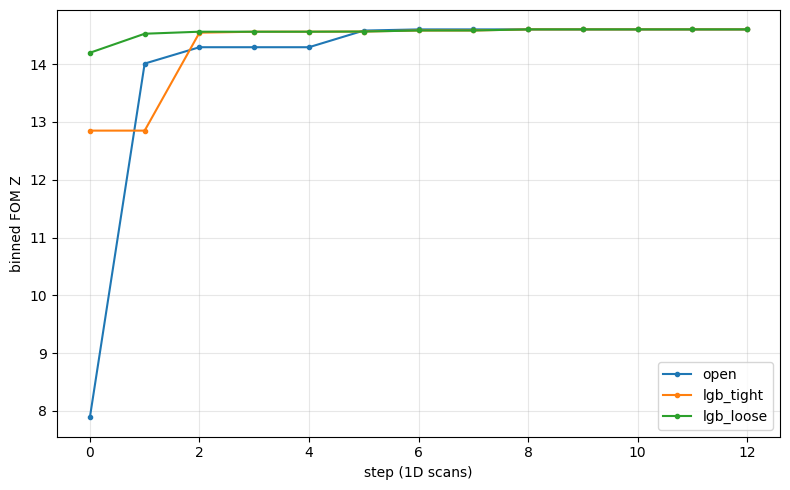

In [6]:
bco.plot_descent_paths(res['paths'], save=f'{PLOTS}/descent_paths.pdf');

Does the bin threshold move the optimum? Rerun the descent with 5 and 20 events per bin.


In [7]:
rows = []
for m in (5, 10, 20):
    r = res if m == 10 else bco.run_optimization(data, starts={'best': res['best_theta']},
                                                 grids=res['grids'], half='A',
                                                 min_bin_count=m, verbose=False)
    th = r['best_theta']
    ev = bco.evaluate_cut(data, th, half='A', min_bin_count=m)
    rows.append(dict(min_bin_count=m, cut=bco.theta_to_cut(th), Z=ev['Z'],
                     n_bins=ev['n_bins'], excess_frac=ev['excess_frac']))
pd.DataFrame(rows)


,min_bin_count,cut,Z,n_bins,excess_frac
0,5,sig_prob>0.384 and fakeD_prob<0.199 and contin...,14.602264,1495,0.136868
1,10,sig_prob>0.384 and fakeD_prob<0.199 and contin...,14.602264,1434,0.135290
2,20,sig_prob>0.384 and fakeD_prob<0.185 and contin...,14.576846,1322,0.135754


Does the estimator move the optimum? The descent above used the default `estimator='unbiased'`; rerun it with `estimator='plain'`.


In [ ]:
r_plain = bco.run_optimization(data, starts={'best': res['best_theta']}, grids=res['grids'],
                               half='A', estimator='plain', verbose=False)
pd.DataFrame([dict(estimator=e, cut=bco.theta_to_cut(r['best_theta']),
                   Z_unbiased=bco.evaluate_cut(data, r['best_theta'], half='A')['Z'],
                   Z_plain=bco.evaluate_cut(data, r['best_theta'], half='A', estimator='plain')['Z'])
              for e, r in (('unbiased (default)', res), ('plain', r_plain))])


## 4. Working points: plateau (tight) and 5% FOM loss (loose)

In [8]:
wps = bco.choose_working_points(data, res['best_theta'], grids=res['grids'], half='A')
print('Z* = %.3f +- %.3f' % (wps['z_star'], wps['sigma_z']))
for k in ('optimum', 'tight', 'loose'):
    print(f'{k:8s}', bco.theta_to_cut(wps[k]))
wps['redundancy_tight']

Z* = 14.602 +- 0.262
optimum  sig_prob>0.384 and fakeD_prob<0.199 and continuum_prob<0.572
tight    sig_prob>0.356 and fakeD_prob<0.251
loose    sig_prob>0.232 and fakeD_prob<0.291


,condition,frac_removed,Z_without
0,sig_prob>0.356,0.499101,11.423628
1,fakeD_prob<0.251,0.372865,13.179952


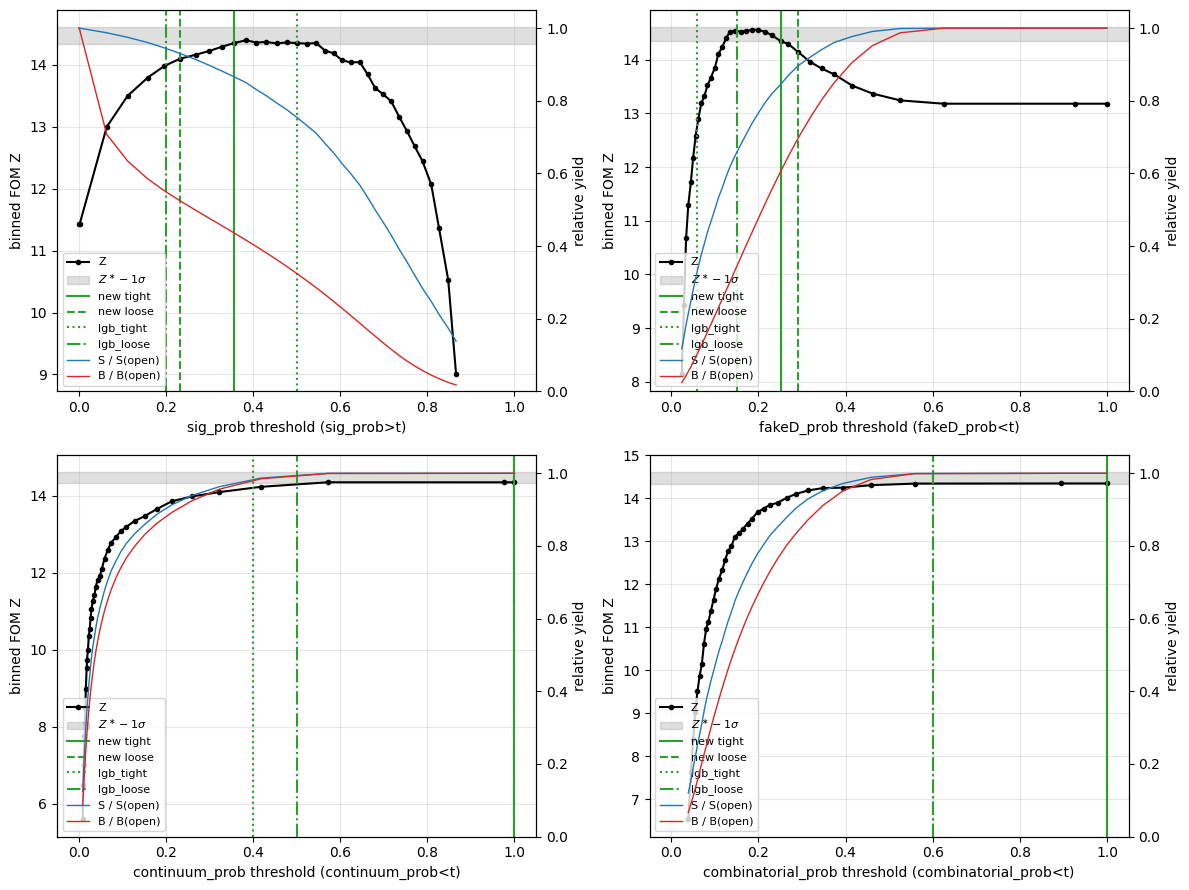

In [9]:
scans = bco.n_minus_1_scans(data, wps['tight'], res['grids'], half='A')
bco.plot_n_minus_1(scans, marks={'new tight': wps['tight'], 'new loose': wps['loose'],
                                 'lgb_tight': util.lgb_tight, 'lgb_loose': util.lgb_loose},
                   sigma_z=wps['sigma_z'], z_ref=wps['z_star'], save=f'{PLOTS}/n_minus_1.pdf');

## 5. Validation: half B, run1 mu, both BCS orders

In [10]:
cuts = {'new tight': wps['tight'], 'new loose': wps['loose'],
        'lgb_tight': util.lgb_tight, 'lgb_loose': util.lgb_loose}
datasets = {'run2 A (opt)': (data, 'A'), 'run2 B (val)': (data, 'B'), 'run1 mu': (data_run1_mu, 'all')}
report = bco.validation_report(cuts, datasets, bcs_orders=('cut_then_bcs', 'bcs_then_cut'))
report.to_csv(f'{PLOTS}/validation_report.csv', index=False)
cols = ['cut_name', 'dataset', 'bcs_order', 'Z', 'n_bins', 'excess_frac', 'S', 'B', f'eff_{bco.FOM_SIGNAL[0]}', 'eff_ratio_sig_norm']
report[cols]

,cut_name,dataset,bcs_order,Z,n_bins,excess_frac,S,B,eff_$D\tau\nu$,eff_ratio_sig_norm
0,new tight,run2 A (opt),cut_then_bcs,14.347054,1465,0.123627,5468.0,264735.0,0.668705,1.029136
1,new tight,run2 A (opt),bcs_then_cut,14.301870,1457,0.127845,5239.0,243890.0,0.640700,1.027921
2,new tight,run2 B (val),cut_then_bcs,13.617184,1457,0.130746,5192.0,264264.0,0.661697,1.015440
3,new tight,run2 B (val),bcs_then_cut,13.538971,1450,0.134434,4970.0,243664.0,0.633410,1.012592
4,new tight,run1 mu,cut_then_bcs,18.732548,741,0.034499,9146.0,453353.0,0.673838,1.058296
5,new tight,run1 mu,bcs_then_cut,18.881251,740,0.035172,8881.0,420697.0,0.654314,1.050796
6,new loose,run2 A (opt),cut_then_bcs,13.879782,1491,0.111418,6258.0,370812.0,0.765317,1.030349
7,new loose,run2 A (opt),bcs_then_cut,13.830384,1486,0.115419,6007.0,344675.0,0.734621,1.027203
8,new loose,run2 B (val),cut_then_bcs,13.237528,1487,0.115682,5949.0,370628.0,0.758282,1.017766
9,new loose,run2 B (val),bcs_then_cut,13.158961,1482,0.120065,5711.0,344403.0,0.727956,1.014535


## 6. Efficiency per MC category

Efficiency = N(category | cut) / N(category | no BDT cut), counted in the D_M signal window, for every truth
category (signal, the six FOM backgrounds, the physics backgrounds) and the totals entering s and b.
Errors are binomial. Two levels:

* **candidate** - BDT cut only, before BCS: the pure MVA performance per candidate (a strict subset, exact errors).
* **event** - BDT cut then BCS: the yields that enter the fit. BCS picks the best candidate *among those that
  pass*, so an event can move to another category when the cut removes its previous best candidate. Such an
  event is lost in one category and gained in another, so a category can exceed its candidate-level value
  (even 100 % in rare cases) and the error is approximate. The difference between the two levels is the
  BCS migration.

`half='all'` uses the whole run2 sample; pass `half='B'` for the validation half only.

In [19]:
eff_cuts = {'new tight': wps['tight'], 'new loose': wps['loose'],
            'lgb_tight': util.lgb_tight, #'lgb_loose': util.lgb_loose,
            'previous_BDTversion_cut': 'sig_prob>0.5 and fakeD_prob<0.06 and continuum_prob<0.25 and combinatorial_prob<0.2' }     # at most 4 per plot
eff_cand = bco.efficiency_table(data, eff_cuts, half='all', level='candidate')
eff_evt = bco.efficiency_table(data, eff_cuts, half='all', level='event')
eff_evt.to_csv(f'{PLOTS}/efficiency_event.csv', index=False)
eff_cand.to_csv(f'{PLOTS}/efficiency_candidate.csv', index=False)
for k in ('optimum', 'tight', 'loose'):
    print(f'{k:8s}', bco.theta_to_cut(wps[k]))

optimum  sig_prob>0.384 and fakeD_prob<0.199 and continuum_prob<0.572
tight    sig_prob>0.356 and fakeD_prob<0.251
loose    sig_prob>0.232 and fakeD_prob<0.291


In [20]:
# event level (fit yields), e+mu; use channel='e' or 'mu' for one channel
bco.efficiency_summary(eff_evt, channel='e+mu')

"efficiency [%], e+mu",group,N before (MC),new tight,new loose,lgb_tight,previous_BDTversion_cut
category,,,,,,
$D\tau\nu$,signal,16025,66.5 ± 0.4,76.2 ± 0.3,24.3 ± 0.3,19.9 ± 0.3
bkg_fakeD,FOM background,3238742,11.7 ± 0.0,16.6 ± 0.0,1.1 ± 0.0,0.8 ± 0.0
bkg_continuum,FOM background,489350,9.3 ± 0.0,15.3 ± 0.1,2.3 ± 0.0,1.3 ± 0.0
bkg_combinatorial,FOM background,400029,20.2 ± 0.1,28.7 ± 0.1,4.5 ± 0.0,2.4 ± 0.0
bkg_hadronicB_secondaryL,FOM background,122717,26.4 ± 0.1,34.2 ± 0.1,7.3 ± 0.1,5.4 ± 0.1
bkg_fakeL,FOM background,89717,14.5 ± 0.1,21.1 ± 0.1,3.6 ± 0.1,2.4 ± 0.1
bkg_fakeTracks,FOM background,83271,15.5 ± 0.1,20.9 ± 0.1,2.9 ± 0.1,2.2 ± 0.1
$D\ell\nu$,physics,410542,65.1 ± 0.1,74.4 ± 0.1,27.5 ± 0.1,23.2 ± 0.1
$D^\ast\tau\nu$,physics,10910,62.4 ± 0.5,72.0 ± 0.4,19.2 ± 0.4,15.8 ± 0.3


In [21]:
bco.efficiency_summary(eff_cand, channel='e+mu')

"efficiency [%], e+mu",group,N before (MC),new tight,new loose,lgb_tight,previous_BDTversion_cut
category,,,,,,
$D\tau\nu$,signal,17279,63.4 ± 0.4,72.8 ± 0.3,22.7 ± 0.3,18.6 ± 0.3
bkg_fakeD,FOM background,3901761,10.6 ± 0.0,15.1 ± 0.0,1.0 ± 0.0,0.8 ± 0.0
bkg_continuum,FOM background,504033,9.2 ± 0.0,15.0 ± 0.1,2.2 ± 0.0,1.3 ± 0.0
bkg_combinatorial,FOM background,446265,18.7 ± 0.1,26.8 ± 0.1,4.1 ± 0.0,2.1 ± 0.0
bkg_hadronicB_secondaryL,FOM background,135470,24.5 ± 0.1,32.0 ± 0.1,6.7 ± 0.1,4.9 ± 0.1
bkg_fakeL,FOM background,96578,13.8 ± 0.1,20.1 ± 0.1,3.4 ± 0.1,2.2 ± 0.0
bkg_fakeTracks,FOM background,98965,13.8 ± 0.1,18.9 ± 0.1,2.5 ± 0.0,1.9 ± 0.0
$D\ell\nu$,physics,437700,62.2 ± 0.1,71.4 ± 0.1,25.9 ± 0.1,21.9 ± 0.1
$D^\ast\tau\nu$,physics,11843,59.1 ± 0.5,68.4 ± 0.4,17.9 ± 0.4,14.7 ± 0.3


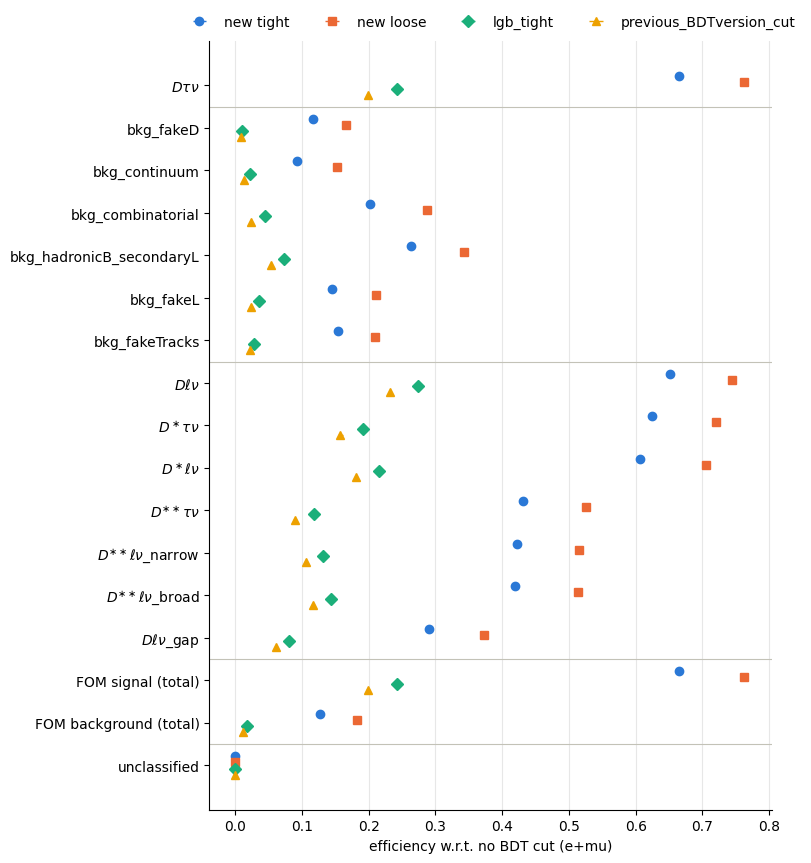

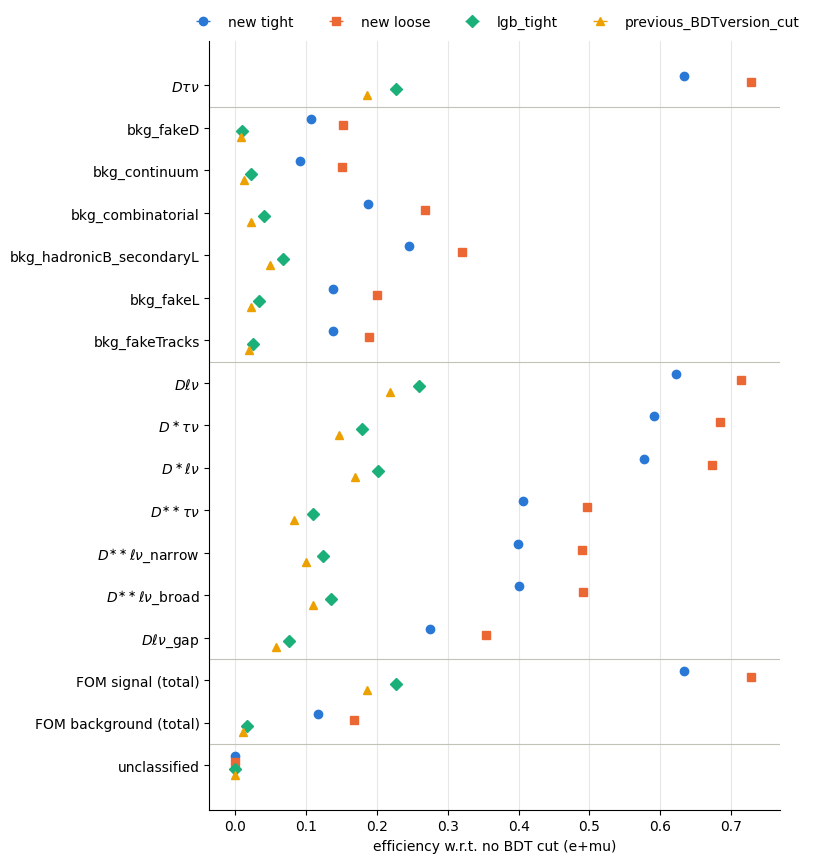

In [22]:
bco.plot_efficiencies(eff_evt, channel='e+mu', log=False, save=f'{PLOTS}/efficiency_event.pdf');
bco.plot_efficiencies(eff_cand, channel='e+mu', log=False, save=f'{PLOTS}/efficiency_candidate.pdf');

## 7. Systematics knob: does the optimum move with eps_bkg?
Yields are raw MC (4 x data luminosity), so `eps_bkg = e` here corresponds to a fractional
background uncertainty of `2e` at data luminosity (e = 0.05 -> 10 %).

In [11]:
eps_rows = []
for eps in (0.0, 0.05, 0.10):
    r = bco.run_optimization(data, starts={'best': res['best_theta']}, grids=res['grids'],
                             half='A', eps_bkg=eps, verbose=False)
    eps_rows.append(dict(eps_bkg=eps, Z=r['summary']['Z'].iloc[0], cut=r['summary']['cut'].iloc[0]))
pd.DataFrame(eps_rows)

,eps_bkg,Z,cut
0,0.00,14.602264,sig_prob>0.384 and fakeD_prob<0.199 and contin...
1,0.05,13.094428,sig_prob>0.545 and fakeD_prob<0.135
2,0.10,11.366376,sig_prob>0.645 and fakeD_prob<0.069


## 8. Next: sculpting check of the new working point
`util.n_minus_1_study(df, bco.theta_to_cut(wps['tight']), ...)` on the candidate-level components,
as in `Plotting/2_Plot_correlations_BDT.ipynb`, and the q2 < 3 data/MC check of the BDT outputs.